In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [18]:
VIDEO_PATH = "../data/sample_video.mp4"

os.makedirs("output_kcf", exist_ok=True)
os.makedirs("output_csrt", exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)
ret, first_frame = cap.read()
fps_video = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

assert ret, f"Не вдалося відкрити відео: {VIDEO_PATH}"
print(f"Роздільна здатність: {first_frame.shape[1]}x{first_frame.shape[0]}, FPS: {fps_video:.1f}, Всього кадрів: {total_frames}")

Роздільна здатність: 640x360, FPS: 30.0, Всього кадрів: 329


### Step 1: Select an object and generate the template
Відобразимо перший кадр із координатною сіткою, щоб точно підібрати координати `(x, y, w, h)` обраного об'єкта, виріжемо шаблон і збережемо його у файл `template.jpg`.

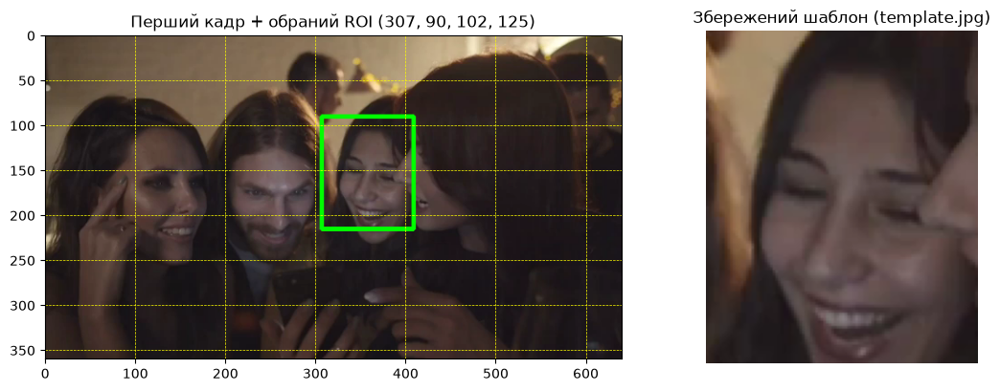

In [19]:
h_img, w_img, _ = first_frame.shape

# Підберіть координати (x, y, w, h) за сіткою нижче під потрібний об'єкт:
bbox = (int(w_img * 0.48), int(h_img * 0.25), int(w_img * 0.16), int(h_img * 0.35))
x, y, w, h = bbox

# Вирізаємо та зберігаємо шаблон
template = first_frame[y:y+h, x:x+w]
cv2.imwrite("template.jpg", template)

# Відображаємо перший кадр із рамкою та шаблон поруч
frame_preview = first_frame.copy()
cv2.rectangle(frame_preview, (x, y), (x + w, y + h), (0, 255, 0), 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(cv2.cvtColor(frame_preview, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Перший кадр + обраний ROI {bbox}")
axes[0].grid(True, color="yellow", linestyle="--", linewidth=0.5)

axes[1].imshow(cv2.cvtColor(template, cv2.COLOR_BGR2RGB))
axes[1].set_title("Збережений шаблон (template.jpg)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Steps 2–5: Initialize and run KCF and CSRT trackers
Функція `run_tracker` ініціалізує обраний трекер на першому кадрі, відстежує об'єкт протягом **100 кадрів**, малює `bounding box` на кожному кадрі, зберігає їх у відповідні папки (`output_kcf/`, `output_csrt/`) та повертає кадри для відображення в ноутбуці.

In [20]:
def run_tracker(tracker_type, video_path, init_bbox, num_frames=15, output_dir="output"):
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    if not ret:
        raise RuntimeError("Помилка читання відео.")

    # Step 2 / Step 5: Ініціалізація трекера
    if tracker_type == "KCF":
        tracker = cv2.TrackerKCF_create()
        color = (255, 140, 0)  # Помаранчевий (BGR)
    elif tracker_type == "CSRT":
        tracker = cv2.TrackerCSRT_create()
        color = (0, 255, 0)    # Зелений (BGR)
    else:
        raise ValueError("Оберіть 'KCF' або 'CSRT'")

    tracker.init(frame, init_bbox)

    tracked_frames = []
    bboxes = []
    start_time = time.time()

    # Step 3: Запуск трекера на 15 кадрах
    for frame_idx in range(num_frames):
        if frame_idx > 0:
            ret, frame = cap.read()
            if not ret:
                break

        success, box = tracker.update(frame)
        vis_frame = frame.copy()

        if success:
            bx, by, bw, bh = [int(v) for v in box]
            bboxes.append((bx, by, bw, bh))
            cv2.rectangle(vis_frame, (bx, by), (bx + bw, by + bh), color, 2)
            cv2.putText(
                vis_frame,
                f"{tracker_type} | Frame {frame_idx + 1}",
                (bx, max(by - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                color,
                2,
            )
        else:
            bboxes.append(None)
            cv2.putText(
                vis_frame,
                f"{tracker_type} | LOST",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 0, 255),
                2,
            )

        # Step 4: Збереження кадру з bounding box
        out_path = os.path.join(output_dir, f"frame_{frame_idx + 1:02d}.jpg")
        cv2.imwrite(out_path, vis_frame)
        tracked_frames.append(vis_frame)

    elapsed = time.time() - start_time
    cap.release()
    return tracked_frames, bboxes, elapsed


NUM_FRAMES = 100

# Запуск KCF (Steps 2–4)
kcf_frames, kcf_boxes, kcf_time = run_tracker("KCF", VIDEO_PATH, bbox, NUM_FRAMES, "output_kcf")

# Запуск CSRT (Step 5)
csrt_frames, csrt_boxes, csrt_time = run_tracker("CSRT", VIDEO_PATH, bbox, NUM_FRAMES, "output_csrt")

print(f"KCF: оброблено {len(kcf_frames)} кадрів за {kcf_time:.3f} с ({len(kcf_frames)/kcf_time:.1f} FPS)")
print(f"CSRT: оброблено {len(csrt_frames)} кадрів за {csrt_time:.3f} с ({len(csrt_frames)/csrt_time:.1f} FPS)")

KCF: оброблено 100 кадрів за 0.755 с (132.4 FPS)
CSRT: оброблено 100 кадрів за 1.765 с (56.6 FPS)


In [21]:
plt.rcParams["animation.embed_limit"] = 100

def show_video_in_notebook(frames_bgr, title="Object Tracking", interval_ms=150):
    # Конвертуємо кадри з BGR (OpenCV) у RGB (Matplotlib)
    frames_rgb = [cv2.cvtColor(f, cv2.COLOR_BGR2RGB) for f in frames_bgr]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axis("off")
    ax.set_title(title)
    img_plot = ax.imshow(frames_rgb[0])

    def update(frame_idx):
        img_plot.set_data(frames_rgb[frame_idx])
        return [img_plot]

    anim = FuncAnimation(
        fig,
        update,
        frames=len(frames_rgb),
        interval=interval_ms,
        blit=True
    )
    plt.close(fig)
    return HTML(anim.to_jshtml())

combined_frames = [np.hstack((k_f, c_f)) for k_f, c_f in zip(kcf_frames, csrt_frames)]

show_video_in_notebook(combined_frames, title="KCF (ліворуч) vs CSRT (праворуч)", interval_ms=150)